<a href="https://colab.research.google.com/github/amansingh4847/NLP/blob/main/unit2/Sentiment%20Analysis%20using%20TextBlob%20and%20VADER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


SENTIMENT ANALYSIS USING TEXTBLOB AND VADER

                                            Text  TextBlob Polarity  Subjectivity TextBlob Sentiment  VADER Compound VADER Sentiment
  I absolutely love this product. It is amazing!              0.625         0.750           Positive           0.862        Positive
The movie was fantastic and highly entertaining.              0.450         0.800           Positive           0.778        Positive
               I am very happy with the service.              1.000         1.000           Positive           0.612        Positive
                This is an excellent experience.              1.000         1.000           Positive           0.572        Positive
           The food was delicious and wonderful.              1.000         1.000           Positive           0.813        Positive
           The product is okay, nothing special.              0.429         0.536           Positive          -0.092        Negative
                       

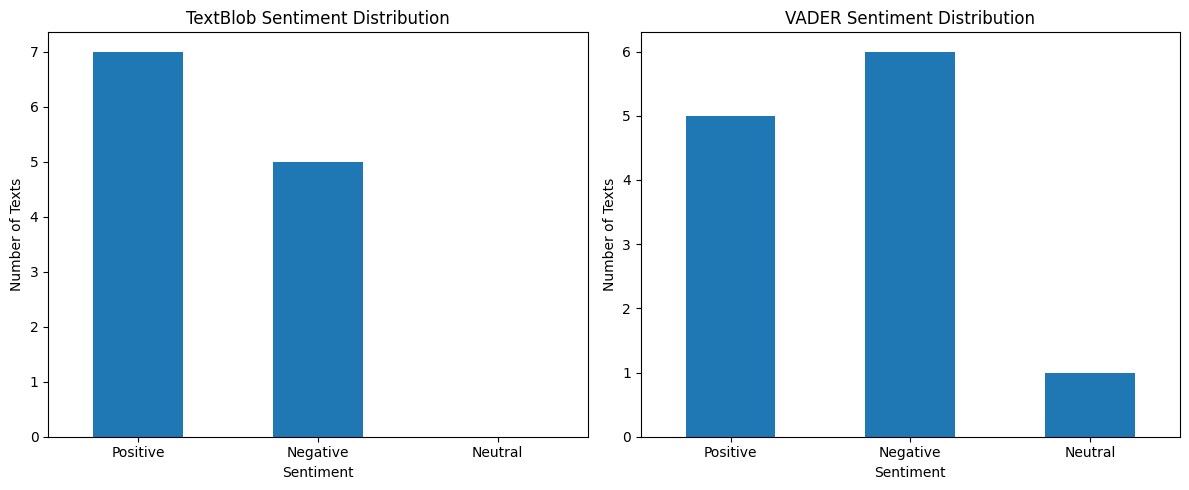

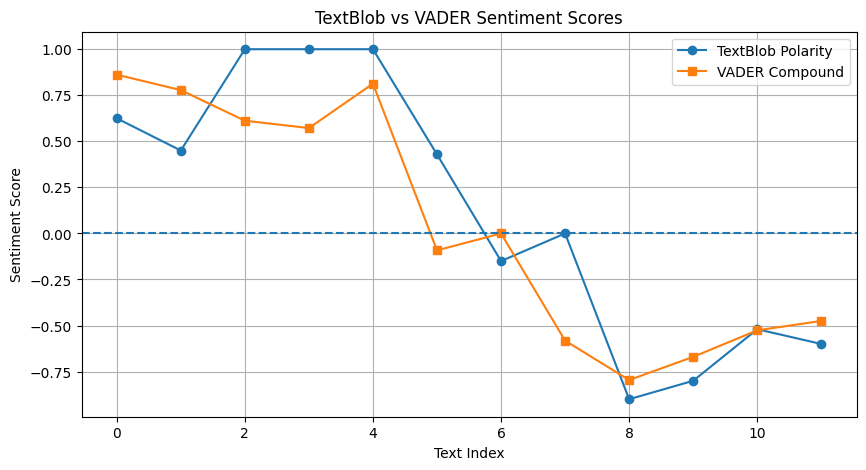


CUSTOM TEXT ANALYSIS
Text: The product is absolutely wonderful and I love it!
TextBlob Polarity: 0.812
TextBlob Sentiment: Positive
VADER Scores: {'neg': 0.0, 'neu': 0.452, 'pos': 0.548, 'compound': 0.8585}
VADER Sentiment: Positive

Sentiment Analysis Completed Successfully!


In [4]:

# Sentiment Analysis using TextBlob and VADER

!pip install -q textblob vaderSentiment

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import pandas as pd
import matplotlib.pyplot as plt

# Sample text dataset
texts = [
    "I absolutely love this product. It is amazing!",
    "The movie was fantastic and highly entertaining.",
    "I am very happy with the service.",
    "This is an excellent experience.",
    "The food was delicious and wonderful.",
    "The product is okay, nothing special.",
    "The movie was average.",
    "The service was neither good nor bad.",
    "I hate this product. It is terrible!",
    "This movie was boring and disappointing.",
    "The customer service was very poor.",
    "I am extremely unhappy with this experience."
]

# Initialize VADER analyzer
vader = SentimentIntensityAnalyzer()

# Sentiment classification functions
def classify_textblob(score):
    if score > 0:
        return "Positive"
    elif score < 0:
        return "Negative"
    return "Neutral"

def classify_vader(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

# Perform sentiment analysis
results = []

for text in texts:
    # TextBlob analysis
    blob = TextBlob(text)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    # VADER analysis
    vader_scores = vader.polarity_scores(text)
    compound = vader_scores['compound']

    results.append({
        'Text': text,
        'TextBlob Polarity': round(polarity, 3),
        'Subjectivity': round(subjectivity, 3),
        'TextBlob Sentiment': classify_textblob(polarity),
        'VADER Compound': round(compound, 3),
        'VADER Sentiment': classify_vader(compound)
    })

# Display results
df = pd.DataFrame(results)

print("\nSENTIMENT ANALYSIS USING TEXTBLOB AND VADER\n")
print(df.to_string(index=False))

# Sentiment distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df['TextBlob Sentiment'].value_counts().reindex(
    ['Positive', 'Negative', 'Neutral'], fill_value=0
).plot(kind='bar', ax=axes[0], title='TextBlob Sentiment Distribution')

df['VADER Sentiment'].value_counts().reindex(
    ['Positive', 'Negative', 'Neutral'], fill_value=0
).plot(kind='bar', ax=axes[1], title='VADER Sentiment Distribution')

for ax in axes:
    ax.set_xlabel('Sentiment')
    ax.set_ylabel('Number of Texts')
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# Compare sentiment scores
plt.figure(figsize=(10, 5))
plt.plot(df.index, df['TextBlob Polarity'], marker='o', label='TextBlob Polarity')
plt.plot(df.index, df['VADER Compound'], marker='s', label='VADER Compound')
plt.axhline(0, linestyle='--')
plt.title('TextBlob vs VADER Sentiment Scores')
plt.xlabel('Text Index')
plt.ylabel('Sentiment Score')
plt.legend()
plt.grid()
plt.show()

# Test custom sentence
custom_text = "The product is absolutely wonderful and I love it!"

blob = TextBlob(custom_text)
vader_result = vader.polarity_scores(custom_text)

print("\nCUSTOM TEXT ANALYSIS")
print("Text:", custom_text)
print("TextBlob Polarity:", round(blob.sentiment.polarity, 3))
print("TextBlob Sentiment:", classify_textblob(blob.sentiment.polarity))
print("VADER Scores:", vader_result)
print("VADER Sentiment:", classify_vader(vader_result['compound']))

print("\nSentiment Analysis Completed Successfully!")
